*© Sabrine Bendimerad · [sbendimerad.github.io](https://sbendimerad.github.io) · Licence [CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/): you may share and adapt this material with credit, for non-commercial use, under the same licence. Datasets keep their own licences.*

# Logistic Regression

## What will you learn in this course? 🧐🧐

This course teaches you the principles of logistic regression, and how to apply this model to binary classification problems. To protect yourself from overfitting, you will keep using a very useful method in supervised machine learning: cross-validation. You already used it in the previous section, with the ```GridSearchCV``` function, to find the optimal penalty parameter for Ridge and LASSO.

* Definition
    * Equation
    * Linear decision boundary
    * Interpretation
* Classification in practice
* How to monitor errors made by the model
     * False positive
     * False negative
     * Watch out for false positives and ESPECIALLY false negatives.
* Metrics for performance assessment
     * Accuracy
     * Recall
     * Precision
     * F1-score
     * Confusion matrix
     * ROC curve, AUC and GINI coefficient

In [ ]:
import plotly.io as pio
import plotly.graph_objects as go
pio.templates["course"] = go.layout.Template(layout_colorway=["#3B47C4", "#E4572E", "#2E7D4F", "#F2C14E", "#8E7CC3", "#4BA3C3", "#111111", "#999999"])
pio.templates.default = "plotly_white+course"
import numpy as np
import pandas as pd
import plotly.express as px
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_classification
from sklearn.metrics import (log_loss, confusion_matrix, accuracy_score, recall_score,
                             precision_score, f1_score, roc_curve, roc_auc_score)

## Definition

Unlike linear regressions, which predict a number, classification models predict a category, or rather the probability of each possible category of the target variable. For example, if you try to predict whether someone will buy your product based on some independent variables, you are facing a classification problem: the categories you are trying to predict are "yes, the person will buy the product" and "no, the person won't buy the product".

Logistic regression is only one type of classification model: there are many others, such as decision trees, SVM (_support vector machine_) or Naive Bayes.

### Model Equation 👩‍🔬

:::tip Intuition
A linear combination of the features, $\beta_0 + X_1\beta_1 + ... + X_p\beta_p$, can be any number, from $-\infty$ to $+\infty$. A probability must stay between 0 and 1. The sigmoid function is the "translator" between the two: very negative scores become probabilities close to 0, very positive scores become probabilities close to 1, and a score of exactly 0 becomes a probability of 50%.
:::

When building a logistic regression model, we assume that there is a function $f$ that links the target variable $Y$ to the explanatory variables in the matrix $X$, as follows:

$$
P(Y=1)=f(X)+\epsilon
$$

Where $\epsilon$ is the residual.

In logistic regression, the function we choose to estimate $f$ is none other than the logistic function (also known as the "sigmoid function" because of its shape)!

$$
\begin{aligned}
f(X) &= \operatorname{sigmoid}(X)  \\
 &= \frac{1}{1+\exp(-X)} \\
 &= \frac{1}{1+\exp(-(\beta_{0}+X_{1}\beta_{1}+...+X_{p}\beta_{p}))} 
\end{aligned}
$$

Where:

$$
\operatorname{sigmoid}(X) = \frac{1}{1+\exp(-X)} 
$$

and

$$
X = \beta_{0}+X_{1}\beta_{1}+...+X_{p}\beta_{p}
$$

The parameters $\beta_0, \beta_1, ..., \beta_p$ are the coefficients learned during training.

In other words, logistic regression looks for a linear combination of the features that separates $Y=0$ from $Y=1$. The probability $P(Y=1)$ is then the logistic (sigmoid) function applied to this linear combination.

### See it with data 🔬: why not a simple linear regression?

The customers dataset tells us the age of 391 customers (we drop the 9 rows with a missing age) and whether they bought the product. Let's encode "Purchased" as 1 (yes) or 0 (no), and fit both a linear regression and a logistic regression of this 0/1 target on the age.

In [ ]:
customers = pd.read_csv("data/customers.csv").dropna(subset=["Age"])
age = customers[["Age"]]
bought = (customers["Purchased"] == "Yes").astype(int)     # 1 = bought, 0 = did not buy

linear = LinearRegression().fit(age, bought)
logistic = LogisticRegression().fit(age, bought)

ages = pd.DataFrame({"Age": np.arange(15, 76)})
print("Linear regression, prediction at 15 and 75 years:", linear.predict(ages.iloc[[0, -1]]).round(2))
print("Logistic regression, P(buy) at 15 and 75 years:   ", logistic.predict_proba(ages.iloc[[0, -1]])[:, 1].round(2))

Linear regression, prediction at 15 and 75 years: [-0.27  1.18]
Logistic regression, P(buy) at 15 and 75 years:    [0.01 0.99]


In [ ]:
fig = px.scatter(x=customers["Age"], y=bought, opacity=0.4, title="Linear vs logistic regression on a 0/1 target",
                 labels={"x": "Age", "y": "Purchased (1 = yes)"})
fig.add_scatter(x=ages["Age"], y=linear.predict(ages), mode="lines", name="linear regression")
fig.add_scatter(x=ages["Age"], y=logistic.predict_proba(ages)[:, 1], mode="lines", name="logistic regression")
fig.add_hline(y=0, line_dash="dot"); fig.add_hline(y=1, line_dash="dot")
fig.show()

**What we see:** the straight line of the linear regression ignores the limits of a probability: it predicts -0.27 for a 15-year-old and 1.18 for a 75-year-old, values that make no sense as probabilities. The logistic regression draws an "S" that stays between 0 and 1 (0.01 at 15 years, 0.99 at 75 years), and is steepest where buyers and non-buyers mix, in the middle of the age range.

### See it with data 🔬: the sigmoid formula, by hand

Let's check that the model really applies the formula above. We read the two learned coefficients $\beta_0$ and $\beta_1$, compute $\frac{1}{1+\exp(-(\beta_0 + \beta_1 \times age))}$ ourselves, and compare with `predict_proba`.

In [ ]:
b0, b1 = logistic.intercept_[0], logistic.coef_[0, 0]
print(f"beta_0 = {b0:.3f}, beta_1 = {b1:.3f}, age where P = 50%: {-b0 / b1:.1f}")

check = pd.DataFrame({"Age": [30, 45, 60]})
check["linear score"] = b0 + b1 * check["Age"]
check["sigmoid by hand"] = 1 / (1 + np.exp(-check["linear score"]))
check["predict_proba"] = logistic.predict_proba(check[["Age"]])[:, 1]
check.round(3)

beta_0 = -7.669, beta_1 = 0.161, age where P = 50%: 47.6


,Age,linear score,sigmoid by hand,predict_proba
0,30,-2.840,0.055,0.055
1,45,-0.426,0.395,0.395
2,60,1.989,0.880,0.880


**What we see:** the two last columns are identical. A negative linear score (age 30) gives a probability below 50%, a positive one (age 60) gives a probability above 50%. The age where the score crosses 0, $-\beta_0 / \beta_1 \approx$ 47.6 years, is where the model hesitates the most (exactly 50%).

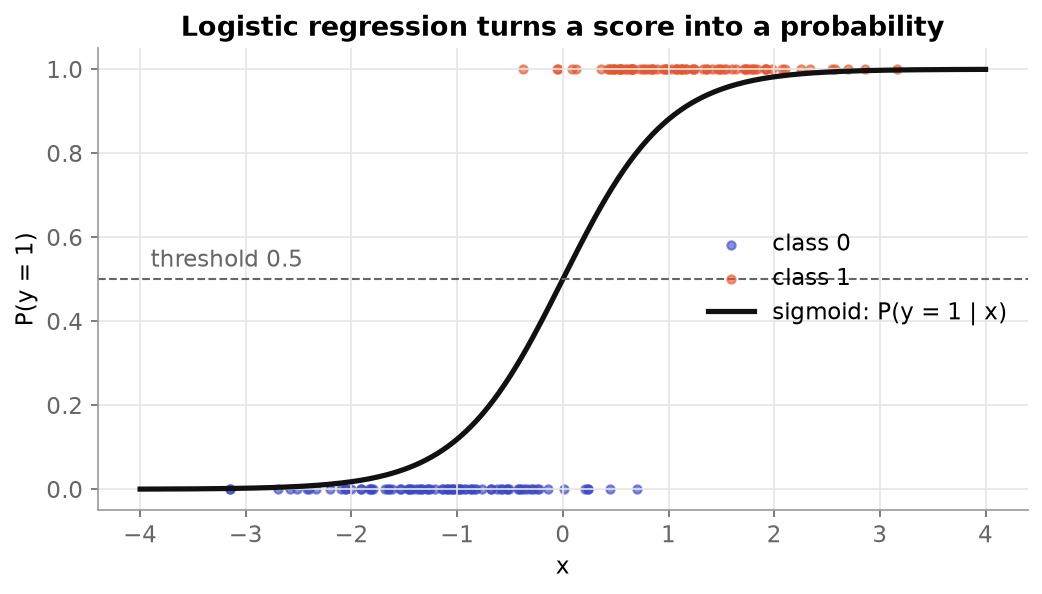

In the graph above, Y represents whether a person will buy a product ($Y = 1$) or will not buy a product ($Y = 0$). The blue curve is the probability that a person will buy ($Y = 1$), depending on the value of $X$. This function keeps $P(Y=1)$ in the interval $[0,1]$, which is the set of values a probability can take. Based on this estimated probability, the algorithm decides in which category to classify each individual.

### Cost Function - Log Loss 📉

:::tip Intuition
The log loss is a "surprise" meter. If the model says 90% and the event happens, it is not very surprised (small loss). If it says 10% and the event happens, it is very surprised (large loss). Being confidently wrong costs much more than being unsure, so the model learns to be confident only when the data justify it.
:::

As you know, in machine learning, we always try to minimize a cost function. For logistic regression, we use the *Log Loss* function, which looks like this:

$$ Log Loss = \sum_{i=0}^n -y_ilog(\hat{y_i}) - (1-y_i)log(1-\hat{y_i}) $$

Where: 

* $y_i$ is your actual target value 
* $\hat{y_i}$ is your model's prediction (the predicted probability that $y_i = 1$)

This formula is a little more complicated, and you don't need to understand every detail. The whole idea is that it pushes the model's predictions closer to the actual target values.

### See it with data 🔬: the log loss rewards confidence... when it is right

For one customer who did buy ($y = 1$), the log loss is simply $-\log(\hat{y})$. Let's compute it for a few predicted probabilities, then compute the average log loss of our age model.

In [ ]:
predicted = np.array([0.99, 0.9, 0.5, 0.1, 0.01])
print(pd.DataFrame({"predicted P(y=1)": predicted, "loss if y = 1": -np.log(predicted)}).round(3))

p_buy = logistic.predict_proba(age)[:, 1]
print(f"\nAverage log loss of the age model: {log_loss(bought, p_buy):.3f}")
print(f"Average log loss if we always say 50%: {log_loss(bought, np.full(len(bought), 0.5)):.3f}")

   predicted P(y=1)  loss if y = 1
0              0.99          0.010
1              0.90          0.105
2              0.50          0.693
3              0.10          2.303
4              0.01          4.605

Average log loss of the age model: 0.404
Average log loss if we always say 50%: 0.693


**What we see:** a confident correct prediction (99%) costs almost nothing (0.010), an unsure one (50%) costs 0.693, and a confidently wrong one (1%) costs 4.605, about 460 times more. Our age model has an average log loss of 0.404, much better than the 0.693 of a model that always answers 50%: training has pushed its probabilities towards the right answers.

### Linear decision boundary

When we studied linear regression, we saw that our predictor could be seen as a line drawn by our model. With logistic regression, this line becomes a boundary: it splits the space of explanatory variables into two areas, one for each category of the target variable. The figure below shows the model's decision boundary in a 2-dimensional feature space:

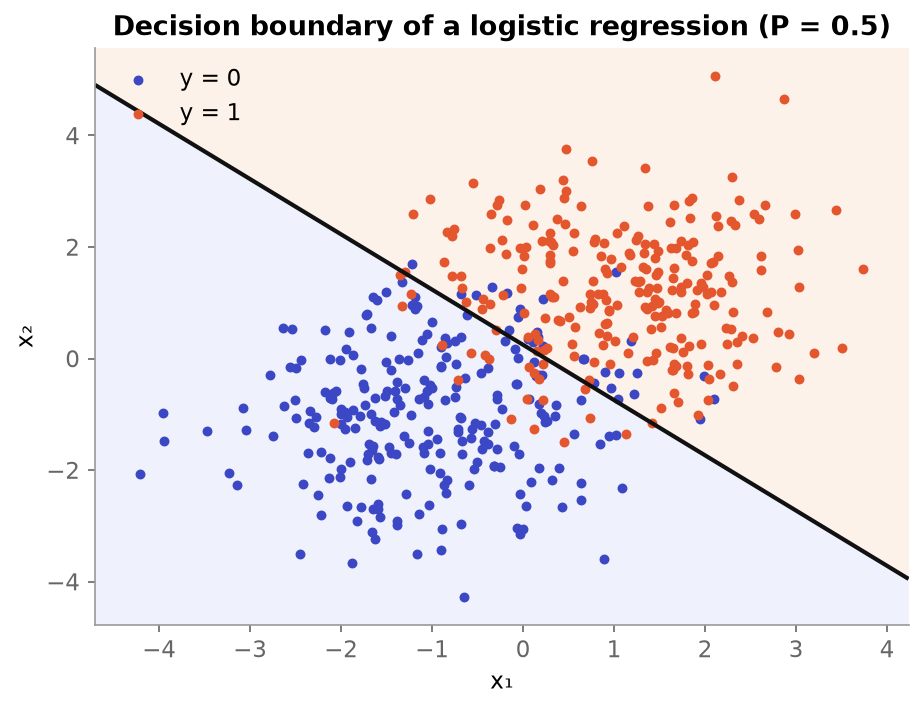

### See it with data 🔬: a decision boundary on real data

The file `exam_scores.txt` contains the grades of 100 students at two exams, and whether they were admitted (1) or not (0). With two explanatory variables, the boundary where $P(Y=1) = 50\%$ is the line $\beta_0 + \beta_1 \times exam_1 + \beta_2 \times exam_2 = 0$. Let's draw it.

In [ ]:
exams = pd.read_csv("data/exam_scores.txt", header=None, names=["exam1", "exam2", "admitted"])
clf = LogisticRegression().fit(exams[["exam1", "exam2"]], exams["admitted"])
(c0,), (c1, c2) = clf.intercept_, clf.coef_[0]

fig = px.scatter(exams, x="exam1", y="exam2", color=exams["admitted"].astype(str),
                 title="Admission: logistic regression decision boundary",
                 labels={"exam1": "Exam 1 grade", "exam2": "Exam 2 grade", "color": "admitted"})
x_line = np.array([30, 100])
fig.add_scatter(x=x_line, y=-(c0 + c1 * x_line) / c2, mode="lines", name="P = 50% boundary")
fig.update_yaxes(range=[25, 105])
fig.show()
print(f"Accuracy on these 100 students: {clf.score(exams[['exam1', 'exam2']], exams['admitted']):.2f}")

Accuracy on these 100 students: 0.88


**What we see:** the boundary is a straight line that separates admitted students (top right) from the others (bottom left). Students above the line get a probability above 50% and are predicted "admitted". A straight line cannot be perfect here: a few points are on the wrong side, and the model classifies 88 of the 100 students correctly.

That's why logistic regression is called a "linear model". Other classification models, like decision trees, can create non-linear decision boundaries.

### Interpretation

Logistic regression is a transposition of multiple linear regression into the interval [0,1]. Like linear regression, it has coefficients: you can analyze their p-values to find which variables have a significant impact on the target variable.
	

### See it with data 🔬: coefficients and p-values

The `statsmodels` library prints the coefficients of a logistic regression with their p-values, like it does for a linear regression:

In [ ]:
import statsmodels.api as sm

logit = sm.Logit(exams["admitted"], sm.add_constant(exams[["exam1", "exam2"]])).fit(disp=0)
table = logit.summary2().tables[1].round(4)
table["P>|z|"] = logit.pvalues.map("{:.1e}".format)   # very small numbers: scientific notation
table

,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
const,-15.0677,3.0853,-4.8837,1.0e-06,-21.1148,-9.0207
exam1,0.1244,0.0280,4.4371,9.1e-06,0.0695,0.1794
exam2,0.1176,0.0259,4.5332,5.8e-06,0.0668,0.1685


**What we see:** both exams have a positive coefficient (a better grade raises the probability of being admitted) and a p-value far below 0.05 (9.1e-06 for exam 1 and 5.8e-06 for exam 2, i.e. about 0.00001): both grades have a significant impact on admission. The coefficients are very close to those of scikit-learn, but not identical: scikit-learn adds a small Ridge-like (`L2`) penalty by default.

## Classification in practice

Now that we have drawn the classification line, we can start interpreting it. Since our model produces probabilities, the points with a probability greater than 50% are assigned to category A, and the points with a probability less than 50% to category B. This is the default classification threshold, but another threshold may be chosen depending on the problem. For example, for bank fraud, data scientists may choose a much lower threshold to catch as many frauds as possible, even if it means blocking many genuine transactions too. A single fraud costs so much trouble, time and money that they would rather delay many genuine payments than let one fraud go through.

Let's take an example. Based on some independent variables, we find that person A has a 60% chance of buying the product: our model therefore considers them a "buyer". On the other hand, person B has only a 45% chance of buying the product: they are considered a "non-buyer".

## How to monitor errors made by the model

Our model is sometimes wrong. False positives and false negatives are the two kinds of errors a classification model can make.

### False positive

Let's continue with the example above. If our model classifies person A as a "buyer" but, in reality, that person does not buy the product, this is a false positive. The model predicted a positive result, but the true value of the target was negative.

### False negative

Now the opposite situation: if person B, whom the model predicted as a non-buyer, does buy the product in the end, this is a false negative. We predicted a negative, but the target variable is positive.

### Watch out for false positives and ESPECIALLY false negatives.

Be careful with false positives and false negatives: depending on what you are trying to predict, a prediction error can have more or less serious consequences. For example, imagine you are a scientist trying to predict earthquakes. With a false negative (you predicted that the earthquake would not happen, and it did), no one was prepared, and many people are in danger. In the opposite situation (you predicted an earthquake, and it did not happen), you have only lost some time and caused some stress by evacuating everyone to safety, but you did not cause any casualties.

Whenever you use a model to make predictions, always ask yourself what is at stake, and make sure the quality of your model matches the objectives you are trying to achieve. Ethics is becoming a major issue in data science. Data and predictive models are all around us, influencing or assisting many of our actions and decisions: it is therefore very important to build these models in a fair and mindful way.

## Metrics for performance assessment

### Confusion matrix

crack

A confusion matrix lets you measure the performance of your model quickly and easily. It shows how many predictions are correct, and how many are false positives and false negatives.

A simple and relevant way to judge your model's performance is to compare its accuracy with the proportion of the majority class in the data. Indeed, the simplest classification model puts all individuals in the most represented class. The accuracy of this trivial model equals the proportion of the majority class in the data. For example, let's assume we have a dataset of bachelor's degree results for a sample of the population. If 70% of the individuals in the sample passed, a model that predicts that everyone passes is right 70% of the time. So it is only worth building a more complex model if its accuracy can be higher than 70%.

This is called comparing your model to a baseline, i.e. to a very simple model. Remember the words often attributed to Leonardo da Vinci: "simplicity is the ultimate sophistication". A similar principle holds in statistics, known as Occam's razor: if two models perform about as well, the simpler one is always preferable.

### See it with data 🔬: building a confusion matrix by hand

Let's use the red wine dataset (1,599 wines) and call a wine "good" (1) when its quality is 7 or more, and "not good" (0) otherwise. Only about 14% of the wines are good. We train a logistic regression on 75% of the wines and predict the other 25%.

In [ ]:
wine = pd.read_csv("data/winequality-red.csv")
X_wine = wine.drop(columns="quality")
y_wine = (wine["quality"] >= 7).astype(int)                # 1 = good wine
print(f"Share of good wines: {y_wine.mean():.1%}")

X_train, X_test, y_train, y_test = train_test_split(X_wine, y_wine, test_size=0.25,
                                                    stratify=y_wine, random_state=0)
wine_model = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_train, y_train)
y_pred = wine_model.predict(X_test)

pd.crosstab(y_test, y_pred, rownames=["true"], colnames=["predicted"])   # by hand

Share of good wines: 13.6%


predicted,0,1
true,,
0,320,26
1,36,18


In [ ]:
print(confusion_matrix(y_test, y_pred))    # the same table, computed by scikit-learn
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f"TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}")

[[320  26]
 [ 36  18]]
TN = 320, FP = 26, FN = 36, TP = 18


**What we see:** a confusion matrix is nothing more than a count of the (true, predicted) pairs, and `pd.crosstab` gives exactly the same table as scikit-learn. Out of 400 test wines, 320 wines are correctly called "not good" (TN), 18 are correctly called "good" (TP), 26 are false alarms (FP) and 36 good wines were missed (FN).

### See it with data 🔬: the accuracy paradox

Now let's compare with the baseline described above, on an even more imbalanced problem: a synthetic dataset where only 5% of the observations are positive (think of fraud). The "lazy" model predicts 0 for everyone.

In [ ]:
X_rare, y_rare = make_classification(n_samples=2000, weights=[0.95], flip_y=0, class_sep=0.8,
                                    random_state=1)
print(f"Share of positives: {y_rare.mean():.1%}")

lazy_pred = np.zeros_like(y_rare)                           # always predict 0
print(f"Lazy model    -> accuracy {accuracy_score(y_rare, lazy_pred):.1%}, "
      f"positives detected: {recall_score(y_rare, lazy_pred):.0%}")

Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_rare, y_rare, stratify=y_rare, random_state=0)
rare_model = LogisticRegression().fit(Xr_train, yr_train)
yr_pred = rare_model.predict(Xr_test)
print(f"Logistic model (test set) -> accuracy {accuracy_score(yr_test, yr_pred):.1%}, "
      f"positives detected: {recall_score(yr_test, yr_pred):.0%}")

Share of positives: 5.0%
Lazy model    -> accuracy 95.0%, positives detected: 0%
Logistic model (test set) -> accuracy 97.4%, positives detected: 52%


**What we see:** the lazy model reaches an accuracy of 95.0% without detecting a single positive case: an impressive score for a useless model. That is why accuracy must always be compared with the share of the majority class, and why we need other metrics that look at the positive class, like recall and precision, defined below. The logistic regression is only a little more accurate (97.4%), but it detects 52% of the positive cases.

### Accuracy

The main evaluation metric, the one sklearn computes for any classification model when you call ```model.score(X,y)```, is the accuracy. The accuracy is the number of correct predictions made by your model divided by the total number of predictions. In other words, it is the proportion of correct predictions.

$$Accuracy = \frac{TN+TP}{TN+TP+FN+FP}$$

### True Positive Rate - (Aka Recall or Sensitivity)

Other evaluation metrics exist for classification problems. The recall is computed for one class of the target variable at a time. Let's call this class A.

The recall is the number of A predicted as A by the model, divided by the total number of A in the whole dataset. In other words, it is the proportion of A that the model detected.

$$TPR = \frac{TP}{TP+FN}$$


In plain English, this is the ability of your model to detect positive events among all the real positive events in your dataset.

### False Positive Rate - (Aka Fallout)


The false positive rate is the "false alarm" rate: the proportion of real negative events that the model classified as positive.

$$FPR = \frac{FP}{FP+TN}$$



### True Negative Rate - (Aka Specificity)

The true negative rate is the ability of your model to correctly classify real negative events as negative.

$$TNR = \frac{TN}{TN+FP}$$

### Precision

The precision is the number of A predicted as A by the model, divided by the total number of observations predicted as A. It is the proportion of predicted A that are actually A.

$$Precision = \frac{TP}{TP+FP}$$

### F1-score

The F1 score is a very useful metric because, unlike accuracy, it takes into account a possible imbalance between the classes of the target variable. The F1 score is the harmonic mean of the recall and the precision for a given class of the target variable.

$$
F1 = 2 \times \frac{Precision \times Recall}{Precision + Recall}
$$

### See it with data 🔬: all the metrics from the confusion matrix

Every metric above is a simple ratio of the four numbers of the confusion matrix. Let's compute them by hand for our wine model, and check them against scikit-learn.

In [ ]:
by_hand = {
    "accuracy": (tp + tn) / (tp + tn + fp + fn),
    "recall (TPR)": tp / (tp + fn),
    "FPR": fp / (fp + tn),
    "specificity (TNR)": tn / (tn + fp),
    "precision": tp / (tp + fp),
}
by_hand["F1"] = 2 * by_hand["precision"] * by_hand["recall (TPR)"] / (by_hand["precision"] + by_hand["recall (TPR)"])
sklearn_values = {"accuracy": accuracy_score(y_test, y_pred), "recall (TPR)": recall_score(y_test, y_pred),
                  "precision": precision_score(y_test, y_pred), "F1": f1_score(y_test, y_pred)}
pd.DataFrame({"by hand": by_hand, "scikit-learn": sklearn_values}).round(3)

,by hand,scikit-learn
accuracy,0.845,0.845
recall (TPR),0.333,0.333
FPR,0.075,NaN
specificity (TNR),0.925,NaN
precision,0.409,0.409
F1,0.367,0.367


**What we see:** the hand-made values match scikit-learn's. They also tell a story that accuracy alone hides: the model is right 84.5% of the time, but it only finds 33.3% (18 out of 54) of the good wines (recall). When it says "good", it is right 40.9% of the time (precision).

### See it with data 🔬: moving the threshold

By default, a wine is predicted "good" when its probability is above 0.5. Let's try 0.3 and 0.7 too, using the predicted probabilities of the wine model.

In [ ]:
proba = wine_model.predict_proba(X_test)[:, 1]          # P(good) for each test wine

rows = []
for threshold in [0.3, 0.5, 0.7]:
    pred = (proba >= threshold).astype(int)
    rows.append({"threshold": threshold, "predicted good": pred.sum(),
                 "precision": precision_score(y_test, pred), "recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred)})
pd.DataFrame(rows).round(3)

,threshold,predicted good,precision,recall,F1
0,0.3,72,0.389,0.519,0.444
1,0.5,44,0.409,0.333,0.367
2,0.7,15,0.600,0.167,0.261


**What we see:** this is the trade-off described in "Classification in practice". With a low threshold (0.3), the model calls more wines "good" (72), so it finds more of the good ones (recall 0.519) but makes more false alarms (precision 0.389). With a high threshold (0.7), it only calls 15 wines "good": it is right more often when it does (precision 0.600) but misses most of the good wines (recall 0.167). Which threshold is best depends on the cost of each kind of error.

### ROC curve and AUC

The ROC curve (receiver operating characteristic curve) shows the overall performance of a binary classification model across all possible classification thresholds.

It plots the true positive rate (_sensitivity_) as a function of the false positive rate (*fall-out*, or *1 - _specificity_*) for all possible values of the threshold.

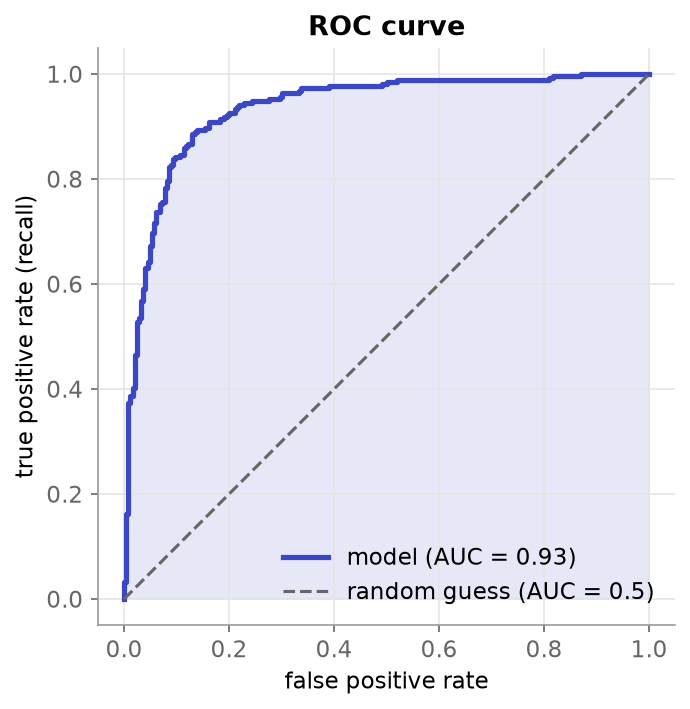

A ROC curve generally looks like the illustration above. A ROC curve that stays close to or below the diagonal is the sign of a terrible model: the higher above the diagonal, the better. The ROC curve shows at a glance how well the model detects positive observations across all possible thresholds. It also gives an overall assessment of the model, summarized by a single number called the AUC (_Area Under the Curve_). The AUC is literally the area under the ROC curve, inside the unit square.

 The AUC can be interpreted as the probability that the model gives a higher score to a randomly selected positive observation than to a randomly selected negative observation.
 

### See it with data 🔬: drawing a ROC curve

A ROC curve is just the (FPR, TPR) pair computed for many thresholds. Let's compute a few points by hand for the wine model, then let scikit-learn compute all of them.

In [ ]:
points = []
for threshold in [0.9, 0.7, 0.5, 0.3, 0.1]:
    pred = (proba >= threshold).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_test, pred).ravel()
    points.append({"threshold": threshold, "FPR": fp_ / (fp_ + tn_), "TPR": tp_ / (tp_ + fn_)})
points = pd.DataFrame(points)
points.round(3)

,threshold,FPR,TPR
0,0.9,0.006,0.019
1,0.7,0.017,0.167
2,0.5,0.075,0.333
3,0.3,0.127,0.519
4,0.1,0.254,0.759


In [ ]:
fpr, tpr, thresholds = roc_curve(y_test, proba)
auc = roc_auc_score(y_test, proba)

fig = px.area(x=fpr, y=tpr, title=f"ROC curve of the wine model (AUC = {auc:.3f})",
              labels={"x": "False positive rate (1 - specificity)", "y": "True positive rate (recall)"})
fig.add_scatter(x=points["FPR"], y=points["TPR"], mode="markers+text", text=points["threshold"],
                textposition="top left", name="our points")
fig.add_scatter(x=[0, 1], y=[0, 1], mode="lines", line_dash="dash", name="random model")
fig.update_layout(xaxis_range=[0, 1], yaxis_range=[0, 1.02])
fig.show()

**What we see:** each threshold gives one point. A high threshold (0.9) is at the bottom left (few alarms, few detections); a low threshold (0.1) is at the top right (many detections, many false alarms). Our hand-computed points sit exactly on scikit-learn's curve, which simply uses every possible threshold. The curve is well above the diagonal, with an AUC of 0.830.

Let's check the interpretation of the AUC given above: "the probability that the model gives a higher score to a randomly selected positive observation than to a randomly selected negative observation". We compare every (good wine, other wine) pair of the test set:

In [ ]:
p_pos = proba[y_test.to_numpy() == 1]       # scores of the good wines
p_neg = proba[y_test.to_numpy() == 0]       # scores of the other wines
pairs_won = (p_pos[:, None] > p_neg[None, :]).mean()
print(f"Pairs where the good wine gets the higher score: {pairs_won:.3f}")
print(f"AUC computed by scikit-learn:                    {auc:.3f}")

Pairs where the good wine gets the higher score: 0.830
AUC computed by scikit-learn:                    0.830


**What we see:** the two numbers are equal: in 83.0% of the (good, not good) pairs, the model gives the higher probability to the good wine. That is exactly what the AUC measures.

### GINI coefficient 

The AUC is also related to the GINI index, which describes the statistical dispersion of the population and is widely used in economics to quantify inequalities.

$$
GINI = 2AUC -1
$$

In theory, the AUC varies between 0 and 1, but models with an AUC below 0.5 (50%) should be discarded immediately: they perform worse than purely random predictions.

In [ ]:
print(f"GINI = 2 x AUC - 1 = 2 x {auc:.3f} - 1 = {2 * auc - 1:.3f}")

GINI = 2 x AUC - 1 = 2 x 0.830 - 1 = 0.661


For our wine model, GINI = 0.661: well above 0, the GINI of a random model.

## Resources 📚📚

- Implementing Logistic Regression - [https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression](https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression)
- Logistic Regression - [https://www.medcalc.org/en/manual/logistic-regression.php](https://www.medcalc.org/en/manual/logistic-regression.php)
- Summary of Probability - [https://www.khanacademy.org/math/precalculus/prob-comb/basic-prob-precalc/v/basic-probability](https://www.khanacademy.org/math/precalculus/prob-comb/basic-prob-precalc/v/basic-probability)
- Confusion Matrix - [https://www.dataschool.io/simple-guide-to-confusion-matrix-terminology/](https://www.dataschool.io/simple-guide-to-confusion-matrix-terminology/)
- False Positives & False Negatives - [https://www.statisticshowto.com/false-positive-definition-and-examples/](https://www.statisticshowto.com/false-positive-definition-and-examples/)
- Understanding AUC - ROC Curve - [https://developers.google.com/machine-learning/crash-course/classification/roc-and-auc](https://towardsdatascience.com/understanding-auc-roc-curve-68b2303cc9c5)
- Sensitivity and Specificity - [https://en.wikipedia.org/wiki/Sensitivity_and_specificity](https://en.wikipedia.org/wiki/Sensitivity_and_specificity)